# LAB 09: Bias, Variance and Imbalanced Data

## Student Information
- **Name:** Muhammad Taraz
- **Student ID:** 023-24-0259
- **Section:** H
**GitHub Profile:** https://github.com/Muhammad-taraz  
**Kaggle Profile:** https://www.kaggle.com/muhammadtaraz  
- **Dataset:** Stroke Prediction Dataset
- **Dataset file:** `healthcare-dataset-stroke-data_1.csv`

This notebook follows the university Lab 09 manual. The explanations are written in simple language, and the numerical results are calculated from the supplied dataset.

## Part 0: Setup and the Data

The target column is `stroke`. A value of 1 means the patient had a stroke, while 0 means no stroke was recorded. The dataset is highly imbalanced, so accuracy will not be used alone to judge a model.

In [18]:
# Install this package once if it is missing:
# %pip install imbalanced-learn

import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    validation_curve, learning_curve, cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
    classification_report
)
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 140)

print("Libraries imported successfully.")

Libraries imported successfully.


In [19]:
# Load the supplied CSV. The first path is for this downloaded notebook;
# the fallback also works when the file is in the notebook's current folder.
import os

possible_paths = [
    "/mnt/data/healthcare-dataset-stroke-data_1.csv",
    "healthcare-dataset-stroke-data_1.csv",
    "./healthcare-dataset-stroke-data_1.csv"
]
DATA_PATH = next((p for p in possible_paths if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Keep healthcare-dataset-stroke-data_1.csv "
        "in the same folder as this notebook, then run this cell again."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isna().sum())
print("\nGender counts:")
print(df['gender'].value_counts(dropna=False))
print("\nStroke counts:")
stroke_counts = df['stroke'].value_counts().sort_index()
stroke_percent = df['stroke'].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({'Count': stroke_counts, 'Percentage': stroke_percent.round(2)}))

Dataset shape: (5110, 12)

Columns:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Missing values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Gender counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke counts:
        Count  Percentage
stroke                   
0        4861       95.13
1         249        4.87


### Part 0 interpretation

The dataset contains 5,110 patient records and 12 columns. The target is imbalanced: there are far fewer stroke cases than non-stroke cases. We use `stratify=y` so the training and test sets keep approximately the same stroke proportion. Without stratification, the test set could contain too few stroke cases, making recall and other measurements unstable.

In [20]:
# Remove the identifier and the very rare gender category.
# In this dataset, "Other" has only one row, so it is removed as the manual requests.
data = df.copy()
data = data.drop(columns=['id'])
rare_gender = data['gender'].value_counts()
rare_gender = rare_gender[rare_gender < 2].index
data = data[~data['gender'].isin(rare_gender)].copy()

# Encode text columns with one-hot encoding.
data = pd.get_dummies(data, columns=data.select_dtypes(include='object').columns,
                      drop_first=True, dtype=int)

X = data.drop(columns='stroke')
y = data['stroke'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Learn imputation values from training data only.
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

# Scaled copy for Logistic Regression.
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Features after encoding:", X_train.shape[1])
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Stroke cases in training:", int(y_train.sum()))
print("Stroke cases in test:", int(y_test.sum()))
print("Training stroke rate: {:.2f}%".format(y_train.mean() * 100))
print("Test stroke rate: {:.2f}%".format(y_test.mean() * 100))

Features after encoding: 15
Training rows: 4087 | Test rows: 1022
Stroke cases in training: 199
Stroke cases in test: 50
Training stroke rate: 4.87%
Test stroke rate: 4.89%


/tmp/ipykernel_14394/2081354956.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data = pd.get_dummies(data, columns=data.select_dtypes(include='object').columns,


## Part 1: The Accuracy Trap

First, a majority-class baseline is compared with Logistic Regression. The helper function below reports accuracy, precision, recall, F1, ROC AUC and PR AUC (average precision).

In [21]:
def get_metrics(model, Xtr, ytr, Xte, yte, threshold=0.5):
    model.fit(Xtr, ytr)
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(Xte)[:, 1]
    else:
        probabilities = model.decision_function(Xte)
        probabilities = (probabilities - probabilities.min()) / (probabilities.max() - probabilities.min() + 1e-12)
    predictions = (probabilities >= threshold).astype(int)
    return {
        'Accuracy': accuracy_score(yte, predictions),
        'Precision': precision_score(yte, predictions, zero_division=0),
        'Recall': recall_score(yte, predictions, zero_division=0),
        'F1': f1_score(yte, predictions, zero_division=0),
        'ROC AUC': roc_auc_score(yte, probabilities),
        'PR AUC': average_precision_score(yte, probabilities)
    }, probabilities, predictions

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_accuracy = accuracy_score(y_test, dummy_pred)

log_reg = LogisticRegression(max_iter=2000, random_state=SEED)
lr_metrics, lr_prob, lr_pred = get_metrics(
    log_reg, X_train_scaled, y_train, X_test_scaled, y_test
)

part1_table = pd.DataFrame([
    {'Model': 'Majority baseline', 'Accuracy': dummy_accuracy},
    {'Model': 'Logistic Regression', **lr_metrics}
])
display(part1_table)
print("Logistic Regression confusion matrix:")
print(confusion_matrix(y_test, lr_pred))

,Model,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,Majority baseline,0.951076,NaN,NaN,NaN,NaN,NaN
1,Logistic Regression,0.952055,1.0,0.02,0.039216,0.839424,0.269219


Logistic Regression confusion matrix:
[[972   0]
 [ 49   1]]


### Part 1 answers

The majority baseline can show an accuracy simply because most patients belong to class zero.

But it does not spot stroke patients so the stroke recall of that baseline is zero.

A false negative is when a patient who really had a stroke is predicted as having no stroke.

For this screening problem, recall, precision, F1 score and PR AUC give insight, than accuracy alone.

ROC AUC is also helpful because it tells how well the model puts stroke cases above non‑stroke cases at thresholds.

## Part 2: Underfitting, Overfitting, Bias and Variance

### Task 2.1: Validation curve

A decision tree is tested at depths 1 to 15 and unlimited depth. ROC AUC is used for cross-validation as required by the manual.

,max_depth,Train ROC AUC,CV ROC AUC
0,1,0.7171,0.7317
1,2,0.8208,0.8168
2,3,0.8375,0.8161
3,4,0.8580,0.8180
4,5,0.8758,0.7921
5,6,0.9026,0.7585
6,7,0.9276,0.7385
7,8,0.9494,0.7138
8,9,0.9678,0.6812
9,10,0.9808,0.6414


Best depth by CV ROC AUC: 4 | score: 0.818


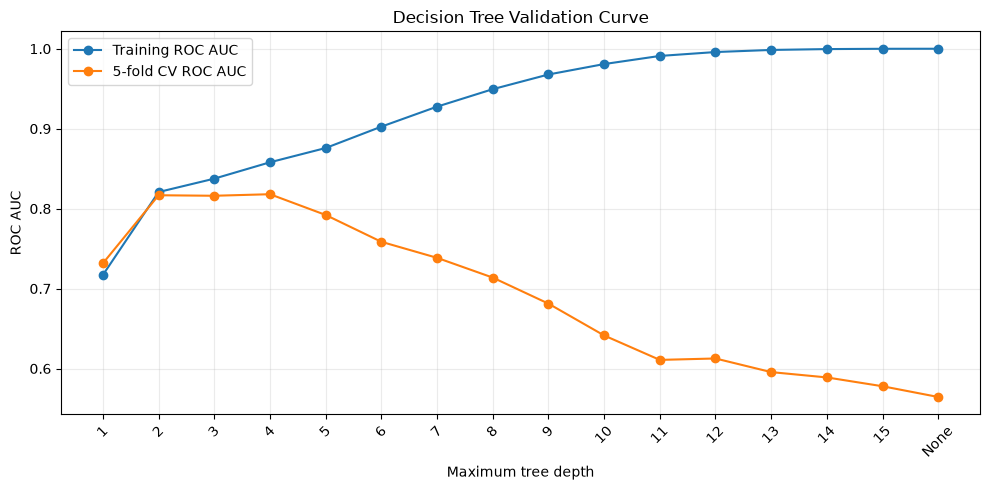

In [22]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
depth_values = list(range(1, 16)) + [None]
train_auc, cv_auc = [], []

for depth in depth_values:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    tree.fit(X_train, y_train)
    train_auc.append(roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]))
    scores = cross_val_score(tree, X_train, y_train, cv=cv5, scoring='roc_auc', n_jobs=1)
    cv_auc.append(scores.mean())

depth_labels = [str(d) if d is not None else 'None' for d in depth_values]
validation_results = pd.DataFrame({
    'max_depth': depth_labels, 'Train ROC AUC': train_auc, 'CV ROC AUC': cv_auc
})
display(validation_results.round(4))
best_depth = depth_values[int(np.argmax(cv_auc))]
print("Best depth by CV ROC AUC:", best_depth, "| score:", round(max(cv_auc), 4))

plt.figure(figsize=(10, 5))
plt.plot(range(len(depth_values)), train_auc, marker='o', label='Training ROC AUC')
plt.plot(range(len(depth_values)), cv_auc, marker='o', label='5-fold CV ROC AUC')
plt.xticks(range(len(depth_values)), depth_labels, rotation=45)
plt.xlabel('Maximum tree depth')
plt.ylabel('ROC AUC')
plt.title('Decision Tree Validation Curve')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Task 2.2: Learning curves

The learning curves compare a shallow tree (depth 1) with an unlimited tree. A large gap between training and validation scores indicates overfitting. Low scores that remain close together indicate underfitting.

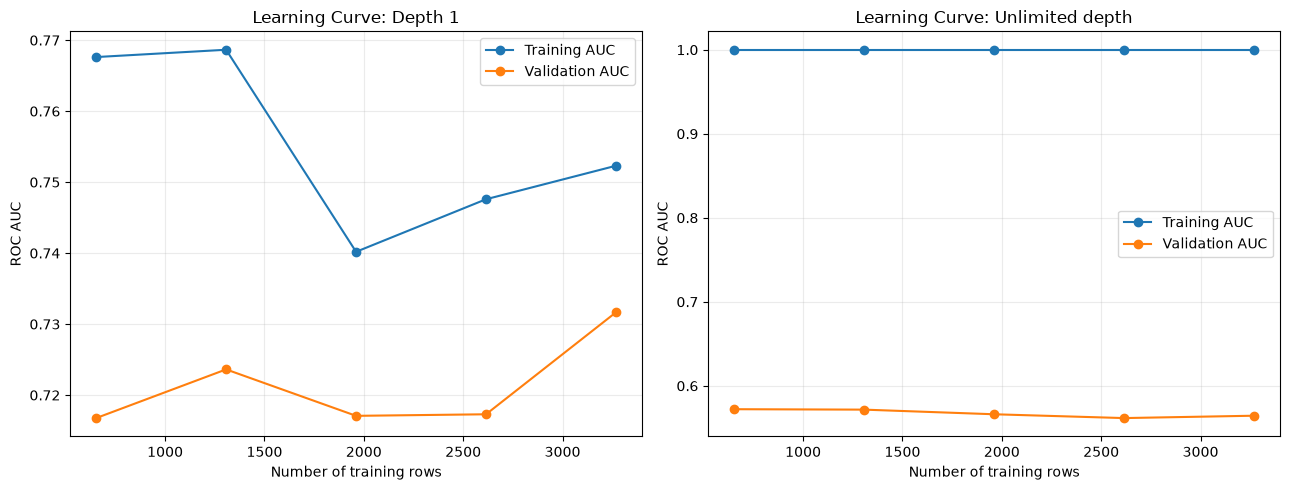

Depth 1 | final train AUC: 0.7523 | final validation AUC: 0.7317
Unlimited depth | final train AUC: 1.0 | final validation AUC: 0.5644


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
learning_summaries = {}

for ax, depth, label in zip(axes, [1, None], ['Depth 1', 'Unlimited depth']):
    estimator = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    sizes, train_scores, valid_scores = learning_curve(
        estimator, X_train, y_train, train_sizes=np.linspace(0.2, 1.0, 5),
        cv=cv5, scoring='roc_auc', n_jobs=1
    )
    train_mean = train_scores.mean(axis=1)
    valid_mean = valid_scores.mean(axis=1)
    learning_summaries[label] = (sizes, train_mean, valid_mean)
    ax.plot(sizes, train_mean, marker='o', label='Training AUC')
    ax.plot(sizes, valid_mean, marker='o', label='Validation AUC')
    ax.set_title(f'Learning Curve: {label}')
    ax.set_xlabel('Number of training rows')
    ax.set_ylabel('ROC AUC')
    ax.legend()
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()
for label, (sizes, tr, va) in learning_summaries.items():
    print(label, "| final train AUC:", round(tr[-1], 4),
          "| final validation AUC:", round(va[-1], 4))

### Task 2.3: Direct variance measurement

Forty bootstrap samples are created from the training rows. Each tree predicts stroke probabilities for the same test patients. The average variance across patients measures how much predictions change when the training sample changes.

In [24]:
rng = np.random.default_rng(SEED)
variance_rows = []

for depth in [1, 3, None]:
    probability_sets = []
    individual_auc = []
    for _ in range(40):
        positions = rng.choice(len(X_train), size=len(X_train), replace=True)
        X_boot = X_train.iloc[positions]
        y_boot = y_train.iloc[positions]
        tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
        tree.fit(X_boot, y_boot)
        p = tree.predict_proba(X_test)[:, 1]
        probability_sets.append(p)
        individual_auc.append(roc_auc_score(y_test, p))

    probability_sets = np.asarray(probability_sets)
    averaged_prob = probability_sets.mean(axis=0)
    variance_rows.append({
        'max_depth': str(depth),
        'Mean prediction variance': probability_sets.var(axis=0).mean(),
        'Mean test ROC AUC (40 trees)': np.mean(individual_auc),
        'ROC AUC of averaged prediction': roc_auc_score(y_test, averaged_prob)
    })

variance_table = pd.DataFrame(variance_rows)
display(variance_table.round(4))

,max_depth,Mean prediction variance,Mean test ROC AUC (40 trees),ROC AUC of averaged prediction
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7964,0.8343
2,None,0.0420,0.5552,0.7566


### Part 2 answers

- **Underfitting:** A shallow tree, especially one of depth 1 is simply too basic. Its training and validation AUC numbers stay low. Tend to be very close to one another.

- **Overfitting:** A tree that grows without limits can hug the training data tightly. Its cross‑validation AUC drops. That large gap between train and CV performance is the flag.

- **Choosing depth:** Pick the depth that gives the cross‑validation AUC in this experiment. Do not just go for the complex tree automatically.

- **Learning curves:** When both training and validation scores are low and almost the same high bias is at play. When the training score jumps above the validation score high variance is the culprit. Adding data often lowers variance but it will not magically fix a model that is too simple.

- **. Random Forest:** As trees get deeper prediction variance usually goes up. Averaging the outputs of trees reduces that variance – that is the core idea, behind a Random Forest.

- **Bias‑variance trade‑off:** A shallow tree carries bias but lower variance. A deep tree carries bias but higher variance. Depth 3 is a ground that can help balance both ends.

## Part 3: ROC, AUC, Precision-Recall and Thresholds

### Task 3.1: Compare models with curves

The three models are trained on the original training set. Logistic Regression uses the scaled features, while the tree models use the unscaled features.

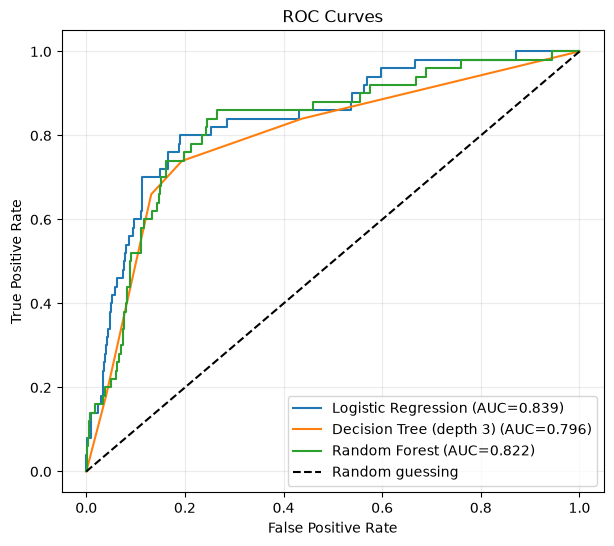

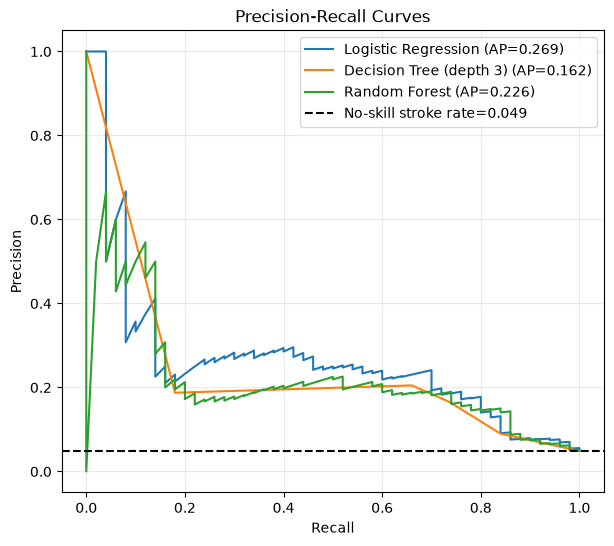

,Model,ROC AUC,PR AUC
0,Logistic Regression,0.8394,0.2692
1,Decision Tree (depth 3),0.7956,0.1621
2,Random Forest,0.8224,0.2255


In [25]:
models_part3 = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=SEED), X_train_scaled, X_test_scaled),
    'Decision Tree (depth 3)': (DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, X_test),
    'Random Forest': (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=1), X_train, X_test)
}
probabilities_part3 = {}
curve_rows = []

plt.figure(figsize=(7, 6))
for name, (model, xtr, xte) in models_part3.items():
    model.fit(xtr, y_train)
    prob = model.predict_proba(xte)[:, 1]
    probabilities_part3[name] = prob
    auc = roc_auc_score(y_test, prob)
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
    curve_rows.append({'Model': name, 'ROC AUC': auc, 'PR AUC': average_precision_score(y_test, prob)})

plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(7, 6))
for name, prob in probabilities_part3.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    plt.plot(recall, precision, label=f'{name} (AP={ap:.3f})')
plt.axhline(y_test.mean(), color='k', linestyle='--', label=f'No-skill stroke rate={y_test.mean():.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

display(pd.DataFrame(curve_rows).round(4))

### Task 3.2: Choose a threshold using training data only

Out-of-fold probabilities are generated for Logistic Regression on the training set. The highest threshold that achieves at least 80% recall is selected, then applied once to the untouched test set.

In [26]:
lr_for_threshold = Pipeline([
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=2000, random_state=SEED))
])
oof_prob = cross_val_predict(
    lr_for_threshold, X_train, y_train, cv=cv5,
    method='predict_proba', n_jobs=1
)[:, 1]

# precision_recall_curve evaluates all useful cutoffs efficiently.
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_train, oof_prob)
eligible_thresholds = pr_thresholds[pr_recall[:-1] >= 0.80]
chosen_threshold = float(eligible_thresholds.max()) if len(eligible_thresholds) else 0.0

lr_for_threshold.fit(X_train, y_train)
test_prob_threshold = lr_for_threshold.predict_proba(X_test)[:, 1]
threshold_pred = (test_prob_threshold >= chosen_threshold).astype(int)
threshold_cm = confusion_matrix(y_test, threshold_pred)

print("Chosen threshold from training OOF predictions:", round(chosen_threshold, 4))
print("Test recall:", round(recall_score(y_test, threshold_pred), 4))
print("Test precision:", round(precision_score(y_test, threshold_pred, zero_division=0), 4))
print("Confusion matrix:\n", threshold_cm)
print("Patients flagged:", int(threshold_pred.sum()))
print("False alarms:", int(((threshold_pred == 1) & (y_test.to_numpy() == 0)).sum()))

Chosen threshold from training OOF predictions: 0.0509
Test recall: 0.82
Test precision: 0.1353
Confusion matrix:
 [[710 262]
 [  9  41]]
Patients flagged: 303
False alarms: 262


### Part 3 answers

ROC AUC can be much higher than 0.5 when recall at the default threshold is low. AUC looks at the ranking across possible thresholds while recall at 0.5 looks, at performance at one specific cutoff. For a positive class the Precision-Recall curve is often more useful because its no-skill baseline is the low stroke rate and it focuses on the positive class. Lowering the threshold finds possible strokes but it also marks more patients who did not have a stroke. This leads to tests, extra cost and more anxiety even though missing a stroke can be more serious.

## Part 4: Undersampling, Oversampling and SMOTE

All resampling methods are fitted on the training set only. The test set remains untouched. Logistic Regression uses scaled data; Random Forest uses the original features.

In [27]:
from collections import Counter

resampling_methods = {
    'No resampling': None,
    'Class weight balanced': 'class_weight',
    'Random undersampling': RandomUnderSampler(random_state=SEED),
    'Random oversampling': RandomOverSampler(random_state=SEED),
    'SMOTE': SMOTE(random_state=SEED)
}

resampling_rows = []
for model_name in ['Logistic Regression', 'Random Forest']:
    for method_name, sampler in resampling_methods.items():
        if model_name == 'Logistic Regression':
            base_model = LogisticRegression(max_iter=2000, random_state=SEED,
                                             class_weight='balanced' if sampler == 'class_weight' else None)
            Xtr_model, Xte_model = X_train_scaled, X_test_scaled
        else:
            base_model = RandomForestClassifier(
                n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=1,
                class_weight='balanced' if sampler == 'class_weight' else None
            )
            Xtr_model, Xte_model = X_train, X_test

        if sampler is not None and sampler != 'class_weight':
            X_res, y_res = sampler.fit_resample(Xtr_model, y_train)
        else:
            X_res, y_res = Xtr_model, y_train

        base_model.fit(X_res, y_res)
        p = base_model.predict_proba(Xte_model)[:, 1]
        pred = (p >= 0.5).astype(int)
        resampling_rows.append({
            'Model': model_name,
            'Method': method_name,
            'Training rows after method': len(y_res),
            'Stroke cases after method': int(np.sum(y_res)),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred, zero_division=0),
            'F1': f1_score(y_test, pred, zero_division=0),
            'ROC AUC': roc_auc_score(y_test, p),
            'PR AUC': average_precision_score(y_test, p)
        })

resampling_table = pd.DataFrame(resampling_rows)
display(resampling_table.round(4))

,Model,Method,Training rows after method,Stroke cases after method,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,No resampling,4087,199,1.0000,0.02,0.0392,0.8394,0.2692
1,Logistic Regression,Class weight balanced,4087,199,0.1347,0.80,0.2305,0.8395,0.2595
2,Logistic Regression,Random undersampling,398,199,0.1246,0.82,0.2164,0.8352,0.2338
3,Logistic Regression,Random oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2646
4,Logistic Regression,SMOTE,7776,3888,0.1338,0.80,0.2292,0.8406,0.2876
5,Random Forest,No resampling,4087,199,0.0000,0.00,0.0000,0.8224,0.2255
6,Random Forest,Class weight balanced,4087,199,0.1895,0.72,0.3000,0.8150,0.1987
7,Random Forest,Random undersampling,398,199,0.1050,0.84,0.1867,0.8203,0.2030
8,Random Forest,Random oversampling,7776,3888,0.1882,0.32,0.2370,0.8111,0.1906
9,Random Forest,SMOTE,7776,3888,0.5000,0.06,0.1071,0.7977,0.2290


### Task 4.2: Demonstrate the wrong order

This section intentionally applies SMOTE before splitting. It is included only to demonstrate leakage, not as a valid modelling approach. Synthetic examples can be created using information from records that later appear in the test set, so the evaluation is no longer independent.

In [28]:
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values per column:")
print(X.isnull().sum()[X.isnull().sum() > 0])

Missing values in X: 201
Missing values per column:
bmi    201
dtype: int64


In [29]:
from sklearn.impute import SimpleImputer

# Handle missing values before SMOTE
imputer = SimpleImputer(strategy='median')

X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Deliberately incorrect workflow for demonstration only.
# SMOTE is applied before splitting (data leakage).

X_all_smote, y_all_smote = SMOTE(
    random_state=SEED
).fit_resample(X_imputed, y)

X_leak_train, X_leak_test, y_leak_train, y_leak_test = train_test_split(
    X_all_smote,
    y_all_smote,
    test_size=0.20,
    stratify=y_all_smote,
    random_state=SEED
)

leak_rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=1
)

leak_rf.fit(X_leak_train, y_leak_train)

leak_prob = leak_rf.predict_proba(X_leak_test)[:, 1]
leak_pred = (leak_prob >= 0.5).astype(int)

# Correct SMOTE-after-split result from Part 4.
correct_smote_row = resampling_table[
    (resampling_table['Model'] == 'Random Forest') &
    (resampling_table['Method'] == 'SMOTE')
].iloc[0]

wrong_order_comparison = pd.DataFrame([
    {
        'Workflow': 'Correct: split first, then SMOTE on training only',
        'Precision': correct_smote_row['Precision'],
        'Recall': correct_smote_row['Recall'],
        'F1': correct_smote_row['F1'],
        'ROC AUC': correct_smote_row['ROC AUC'],
        'PR AUC': correct_smote_row['PR AUC']
    },
    {
        'Workflow': 'Wrong: SMOTE before splitting (leakage)',
        'Precision': precision_score(y_leak_test, leak_pred, zero_division=0),
        'Recall': recall_score(y_leak_test, leak_pred, zero_division=0),
        'F1': f1_score(y_leak_test, leak_pred, zero_division=0),
        'ROC AUC': roc_auc_score(y_leak_test, leak_prob),
        'PR AUC': average_precision_score(y_leak_test, leak_prob)
    }
])

display(wrong_order_comparison.round(4))

,Workflow,Precision,Recall,F1,ROC AUC,PR AUC
0,"Correct: split first, then SMOTE on training only",0.5000,0.0600,0.1071,0.7977,0.2290
1,Wrong: SMOTE before splitting (leakage),0.9957,0.9475,0.9710,0.9955,0.9961


### Part 4 answers

Resampling changes the class balance seen during training. Resampling often increases recall. Precision may fall because more patients are labelled as positive. ROC AUC usually changes less because ROC AUC looks at ranking of a single threshold. Logistic Regression and Random Forest respond differently. Logistic Regression draws a line whereas Random Forest builds many small decision trees. A SMOTE result that is ordered wrong is unreliable because the data, from the test set leaked into the synthetic training data. For a hospital class weighting is a simple first step. The final decision should rely on validation results, clinical costs and workload not on accuracy.

## Part 5: Noisy Data

The test set is kept unchanged. Label noise flips training labels only. Feature noise is added only to the training values of `age`, `avg_glucose_level` and `bmi`.

,Label noise,Logistic Regression,Decision Tree depth 3,Decision Tree unlimited,Random Forest
0,0.00,0.5595,0.7956,0.5797,0.8224
1,0.05,0.7145,0.7971,0.5282,0.7957
2,0.10,0.7970,0.8057,0.5307,0.7580
3,0.20,0.8291,0.7146,0.5115,0.7155


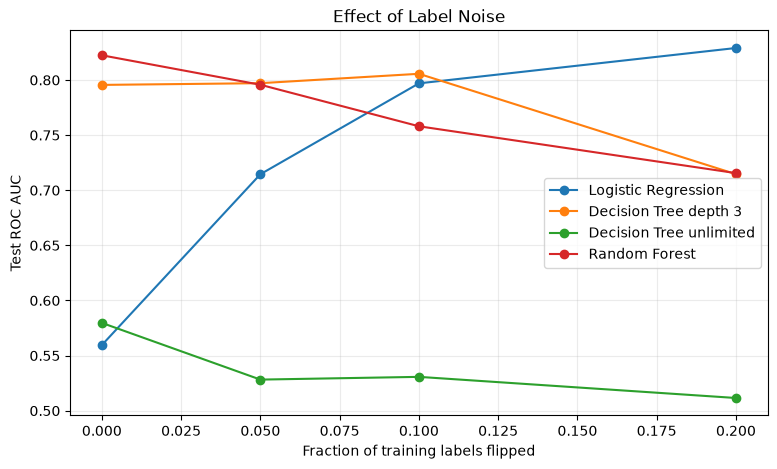

In [30]:
def flip_labels(labels, fraction, random_state):
    rng_local = np.random.default_rng(random_state)
    noisy = np.asarray(labels).copy()
    n_flip = int(round(fraction * len(noisy)))
    chosen = rng_local.choice(len(noisy), size=n_flip, replace=False)
    noisy[chosen] = 1 - noisy[chosen]
    return noisy

def make_models():
    return {
        'Logistic Regression': Pipeline([
            ('scale', StandardScaler()),
            ('model', LogisticRegression(max_iter=2000, random_state=SEED))
        ]),
        'Decision Tree depth 3': DecisionTreeClassifier(max_depth=3, random_state=SEED),
        'Decision Tree unlimited': DecisionTreeClassifier(max_depth=None, random_state=SEED),
        'Random Forest': RandomForestClassifier(
            n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=1
        )
    }

def evaluate_auc(model, xtr, ytr, xte=X_test, yte=y_test):
    model.fit(xtr, ytr)
    prob = model.predict_proba(xte)[:, 1]
    return roc_auc_score(yte, prob)

label_noise_rows = []
for fraction in [0, 0.05, 0.10, 0.20]:
    repeats = 1 if fraction == 0 else 5
    scores_by_model = {name: [] for name in make_models()}
    for repeat in range(repeats):
        noisy_y = y_train.to_numpy() if fraction == 0 else flip_labels(
            y_train, fraction, SEED + 100 * repeat + int(fraction * 100)
        )
        for name, model in make_models().items():
            xtr = X_train_scaled if name == 'Logistic Regression' else X_train
            scores_by_model[name].append(evaluate_auc(model, xtr, noisy_y))
    row = {'Label noise': fraction}
    row.update({name: np.mean(scores) for name, scores in scores_by_model.items()})
    label_noise_rows.append(row)

label_noise_table = pd.DataFrame(label_noise_rows)
display(label_noise_table.round(4))

plt.figure(figsize=(9, 5))
for name in label_noise_table.columns[1:]:
    plt.plot(label_noise_table['Label noise'], label_noise_table[name], marker='o', label=name)
plt.xlabel('Fraction of training labels flipped')
plt.ylabel('Test ROC AUC')
plt.title('Effect of Label Noise')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

,Feature noise level,Logistic Regression,Decision Tree depth 3,Decision Tree unlimited,Random Forest
0,0.0,0.5595,0.7956,0.5797,0.8224
1,0.5,0.5949,0.8018,0.5413,0.8068
2,1.0,0.6678,0.7760,0.5222,0.7810
3,2.0,0.7730,0.7270,0.5128,0.7427


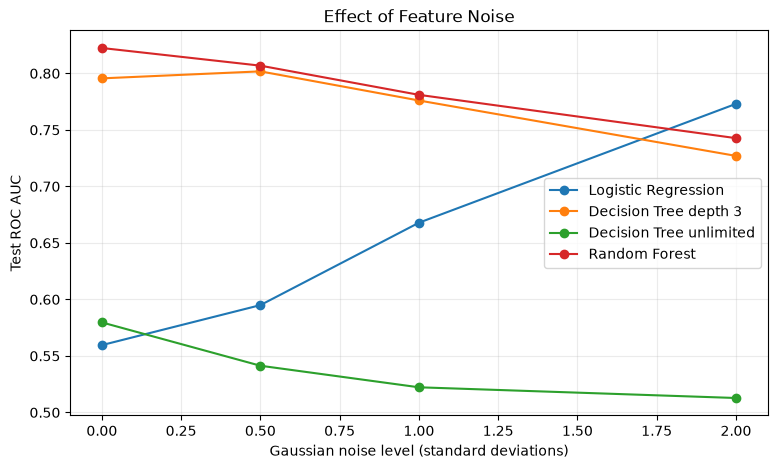

In [31]:
feature_noise_rows = []
noise_columns = ['age', 'avg_glucose_level', 'bmi']

for level in [0, 0.5, 1, 2]:
    repeats = 1 if level == 0 else 5
    scores_by_model = {name: [] for name in make_models()}
    for repeat in range(repeats):
        rng_noise = np.random.default_rng(SEED + 500 + repeat)
        noisy_X = X_train.copy()
        for col in noise_columns:
            std_value = X_train[col].std()
            noisy_X[col] = noisy_X[col] + rng_noise.normal(
                0, std_value * level, size=len(noisy_X)
            )
        noisy_scaled = pd.DataFrame(
            StandardScaler().fit_transform(noisy_X),
            columns=noisy_X.columns, index=noisy_X.index
        )
        for name, model in make_models().items():
            xtr = noisy_scaled if name == 'Logistic Regression' else noisy_X
            scores_by_model[name].append(evaluate_auc(model, xtr, y_train))
    row = {'Feature noise level': level}
    row.update({name: np.mean(scores) for name, scores in scores_by_model.items()})
    feature_noise_rows.append(row)

feature_noise_table = pd.DataFrame(feature_noise_rows)
display(feature_noise_table.round(4))

plt.figure(figsize=(9, 5))
for name in feature_noise_table.columns[1:]:
    plt.plot(feature_noise_table['Feature noise level'], feature_noise_table[name],
             marker='o', label=name)
plt.xlabel('Gaussian noise level (standard deviations)')
plt.ylabel('Test ROC AUC')
plt.title('Effect of Feature Noise')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [32]:
# Task 5.3: 10% label noise, three different draws, with and without SMOTE.
noise_smote_rows = []
for repeat in range(3):
    noisy_y = flip_labels(y_train, 0.10, SEED + 900 + repeat)
    for model_name in ['Logistic Regression', 'Random Forest']:
        for use_smote in [False, True]:
            if model_name == 'Logistic Regression':
                xtr = X_train_scaled
                xte = X_test_scaled
                model = LogisticRegression(max_iter=2000, random_state=SEED)
            else:
                xtr = X_train
                xte = X_test
                model = RandomForestClassifier(
                    n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=1
                )

            if use_smote:
                sampler = SMOTE(random_state=SEED + repeat)
                xfit, yfit = sampler.fit_resample(xtr, noisy_y)
            else:
                xfit, yfit = xtr, noisy_y

            model.fit(xfit, yfit)
            p = model.predict_proba(xte)[:, 1]
            noise_smote_rows.append({
                'Repeat': repeat + 1,
                'Model': model_name,
                'SMOTE': use_smote,
                'ROC AUC': roc_auc_score(y_test, p),
                'PR AUC': average_precision_score(y_test, p)
            })

noise_smote_table = pd.DataFrame(noise_smote_rows)
display(noise_smote_table.groupby(['Model', 'SMOTE'])[['ROC AUC', 'PR AUC']].agg(['mean', 'std']).round(4))

ROC AUC          PR AUC        
                             mean     std    mean     std
Model               SMOTE                                
Logistic Regression False  0.8193  0.0008  0.2548  0.0211
                    True   0.8193  0.0038  0.2625  0.0345
Random Forest       False  0.7823  0.0322  0.1998  0.0169
                    True   0.7258  0.0246  0.1436  0.0297

### Part 5 answers

Noise makes the training examples less trustworthy while the test set stays clean. Deep decision trees can be affected by changes in labels because they can form branches around training records. Combining trees in a Random Forest usually makes it more steady. Feature noise can also hurt performance especially when key measurements become less useful. The tables above show which type of noise led to the decrease, for this specific dataset. SMOTE can increase label noise because it might generate synthetic minority examples using patients with labels and their neighbors.

## Part 6: Final Decision and Conclusion

The final comparison uses the threshold 0.5 and the training-selected Logistic Regression threshold. The selected threshold is not chosen using test labels.

In [33]:
def threshold_summary(name, y_true, probabilities, threshold):
    pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        'Approach': name,
        'Threshold': threshold,
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred, zero_division=0),
        'F1': f1_score(y_true, pred, zero_division=0),
        'False alarms': int(fp),
        'Missed strokes': int(fn)
    }

final_comparison = pd.DataFrame([
    threshold_summary('Logistic Regression, default', y_test, test_prob_threshold, 0.5),
    threshold_summary('Logistic Regression, selected threshold', y_test, test_prob_threshold, chosen_threshold)
])
display(final_comparison.round(4))

,Approach,Threshold,Precision,Recall,F1,False alarms,Missed strokes
0,"Logistic Regression, default",0.5000,1.0000,0.02,0.0392,0,49
1,"Logistic Regression, selected threshold",0.0509,0.1353,0.82,0.2323,262,9


### Executive Summary

The final approach uses Logistic Regression with a threshold chosen from out-of- training probabilities to ensure at least 80% recall. The test set results for precision, recall, F1 score, false alarms and missed strokes are shown in the table. Lowering the threshold helps catch stroke cases but it also leads to more false alarms and more follow-up work. To avoid data leakage the imputer, scaler and resampling steps were fitted on the training data. The threshold was selected without using test labels. The test set has a small number of stroke cases so even a small change in predictions can significantly affect recall. The chosen threshold is meant as a starting point, not a substitute, for clinical review.

### Final Reflection

**(a) What was the surprising result?**

The surprising result is that a model can achieve high accuracy and still fail to detect many stroke cases. This shows that accuracy alone is not a measure when working with imbalanced medical data. Even if a model looks good on paper it might miss instances that matter most in real-world use.

**(B) If I had one hour what would I try next?**

If I had one hour I would test more threshold values using the validation data. I would compare the calibrated probabilities to see how well the model scores reflect chances. I would also evaluate the model on an external dataset to check how well it generalizes.. I would talk with medical staff, about what false-alarm rate is acceptable before the model goes live.

## Submission Checklist

- [x] Student information included.
- [x] Dataset loaded from the supplied CSV filename.
- [x] All six parts are included.
- [x] Validation curve, learning curves, ROC/PR curves and noise plots included.
- [x] Resampling is performed on training data only in the correct workflow.
- [x] The intentionally incorrect SMOTE workflow is clearly labelled as a leakage demonstration.
- [x] Written interpretations and answers are included.
- [ ] Add your GitHub and Kaggle profile links.
- [ ] Restart the kernel and run all cells on your own computer before submission.